<a href="https://colab.research.google.com/github/miso-20/ESSA/blob/main/ESAA_OB_Project3_%ED%9B%84%EC%B2%98%EB%A6%AC_%EC%84%B1%EB%8A%A5%ED%96%A5%EC%83%81_%EC%8B%9C%ED%98%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 제주 특산물 가격 예측 — 최종 노트북 (전처리 → 모델 → 후처리 → 제출)

**예측식**: 예측 가격 = 거래 확률 × 기준가격 × 변화율

| 단계 | 내용 |
|---|---|
| 1~2 | 환경 설정, 데이터 불러오기 |
| 3 | EDA (발표 인사이트용) |
| 4 | 전처리 · 피처 생성 (예측 시점 × 시계열 × 1~28일 뒤) |
| 5 | 피처 확장 (작년 대비 가격 수준, 품목 공통 작년 변화율 등) |
| 6 | 검증 설계 (예측 시점 4곳, 누수 없음) |
| 7 | 모델 정의 (분류 1개 + 회귀 2개) |
| 8 | **성능 향상 실험**: v2 재현 → 피처 · 가중치 실험을 하나씩 추가, 채택 규칙으로 자동 선택 |
| 9 | **후처리 실험**: 일요일 0, 회귀 비중, 확률 보정, 가격 배율, 계절 평균 섞기 |
| 10 | 최종 학습(시드 3개 평균) → 제출 파일 |
| 11 | 결과 분석 (발표용: 예측 유의성, 오차 기여도, 피처 중요도) |

**실행 방법**: 1번 셀의 `USE_DRIVE` · `DATA_DIR`만 확인하고 **런타임 → 모두 실행**. (Colab CPU 기준 약 20~30분)

**대회 규칙 체크**: 2023-03-03까지의 정보만 사용 · 외부 데이터 없음 · Pseudo Labeling 없음 · 시드 고정으로 재현 가능

# 1. 환경 설정

In [ ]:
!pip install -q koreanize-matplotlib lightgbm statsmodels
import sys, os, platform, time, logging, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import sklearn, lightgbm as lgb

warnings.filterwarnings('ignore')
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
try:
    import koreanize_matplotlib
except ImportError:
    plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:,.3f}'.format)

# ── 데이터 경로: 이 셀에서만 정한다 ──────────────────────────────
USE_DRIVE = True    # 구글 드라이브의 데이터 사용 / 대회 제출용 코드는 False (./data/ 사용)
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/ESAA/OB 프로젝트/ESAA_OB_Project3_data/'   # ← 본인 폴더로 수정
else:
    DATA_DIR = './data/'

TRAIN_PATH = DATA_DIR + 'train.csv'
TEST_PATH  = DATA_DIR + 'test.csv'
TRADE_PATH = DATA_DIR + 'international_trade.csv'
SUB_PATH   = DATA_DIR + 'sample_submission.csv'
OUT_DIR    = DATA_DIR                      # 제출 파일 저장 위치
if not os.path.exists(TRAIN_PATH):
    raise FileNotFoundError(f'{TRAIN_PATH} 가 없습니다 → DATA_DIR 경로를 확인하세요 (끝에 / 포함)')

SEED = 42
np.random.seed(SEED)
ITEMS = ['TG', 'CR', 'CB', 'RD', 'BC']
ITEM_KR = {'TG': '감귤', 'CR': '당근', 'CB': '양배추', 'RD': '무', 'BC': '브로콜리'}
H = 28

# 대회 제출 규칙: 개발 환경 및 라이브러리 버전 기재
print('OS:', platform.platform(), '| Python', sys.version.split()[0])
print('numpy', np.__version__, '| pandas', pd.__version__, '| lightgbm', lgb.__version__,
      '| scikit-learn', sklearn.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OS: Linux-6.6.159+-x86_64-with-glibc2.39 | Python 3.13.18
numpy 2.4.6 | pandas 2.2.3 | lightgbm 4.6.0 | scikit-learn 1.6.1


# 2. 데이터 불러오기 → 날짜 × 시계열 행렬로 변환

가격 행렬: (1551, 39) | 결측(=test 구간) 행 수: 28
거래일 비율: 40.3%


series,BC_A_J,BC_A_S,BC_B_J,BC_B_S,BC_C_J,BC_C_S,BC_D_J,BC_E_J
2023-03-29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-03-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-03-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


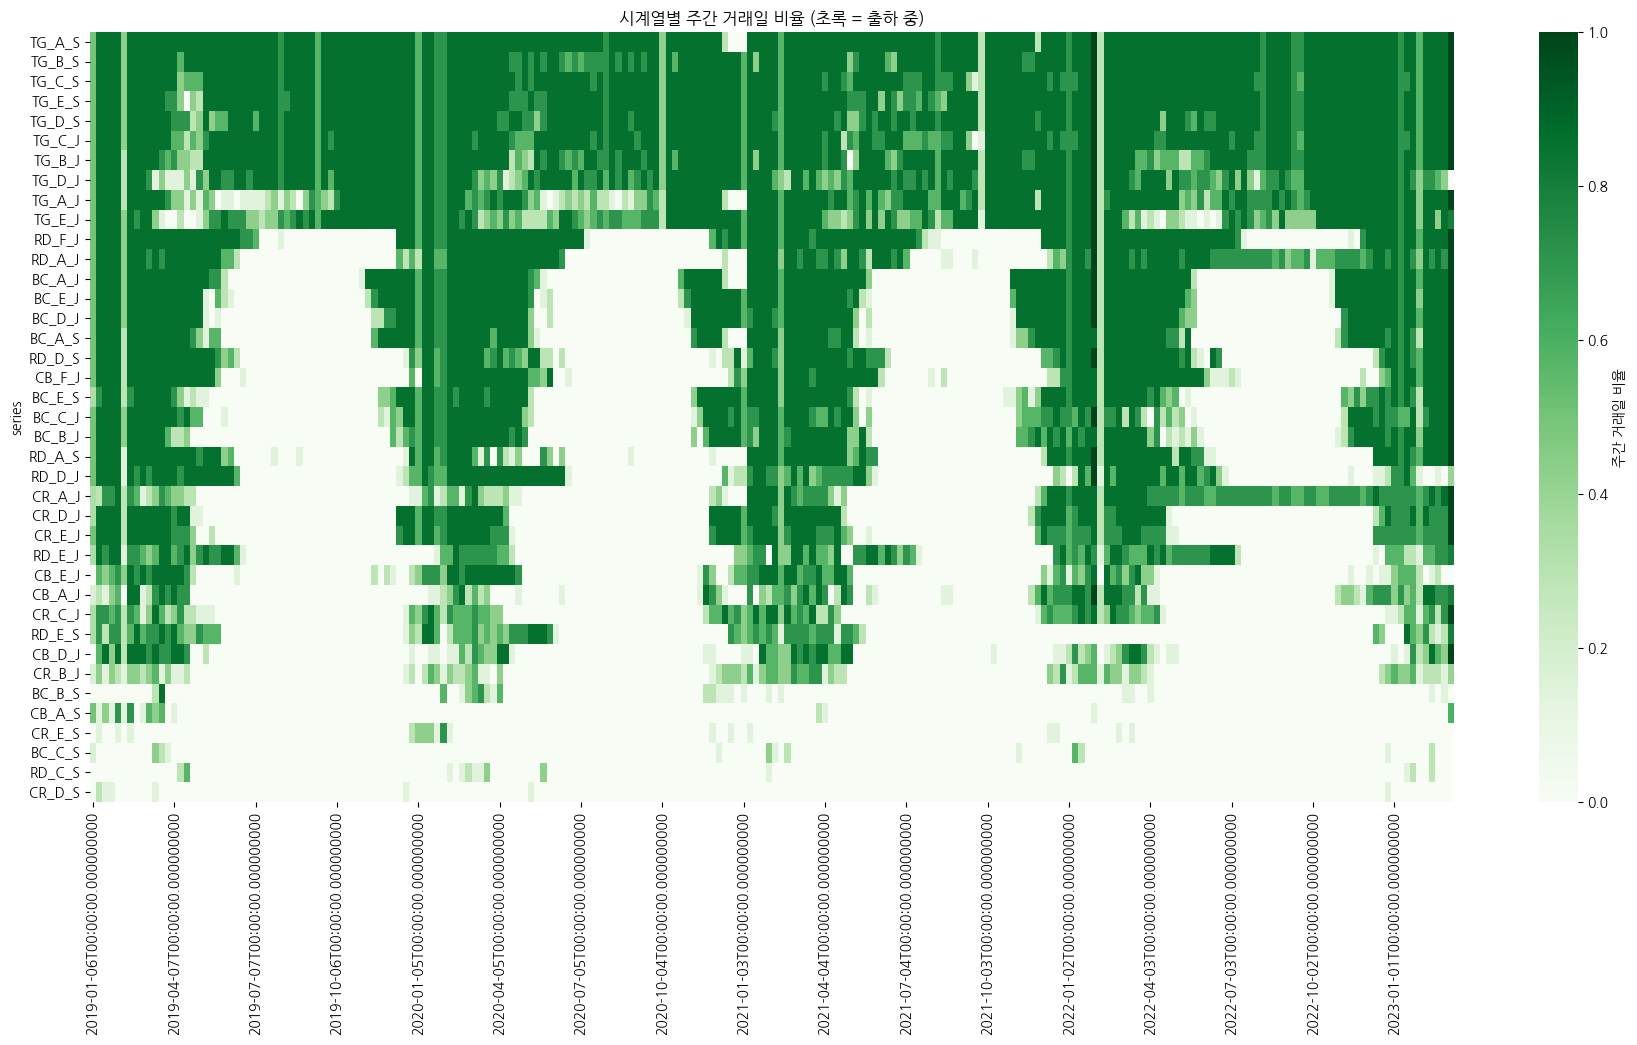

,2019년,2020년,2021년,2022년,2023년,평균
series,,,,,,
CR_D_S,0,0,0,0,0,0.000
BC_C_S,0,0,0,1,0,0.200
CR_E_S,0,1,0,0,0,0.200
RD_C_S,1,0,0,0,0,0.200
CB_A_S,4,0,0,0,1,1.000
BC_B_S,1,4,0,0,0,1.200
CR_B_J,1,2,9,4,2,4.000
CB_D_J,13,5,13,6,4,9.200
CB_A_J,9,5,16,15,7,11.200


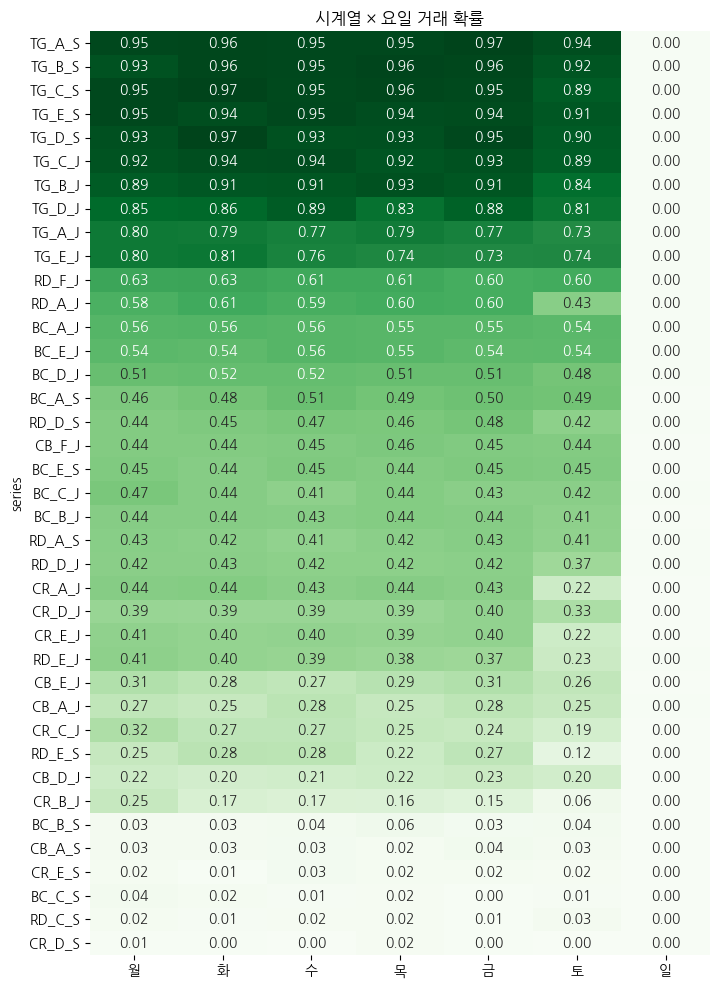

In [ ]:
train = pd.read_csv(TRAIN_PATH).rename(columns={'supply(kg)': 'supply', 'price(원/kg)': 'price'})
test = pd.read_csv(TEST_PATH)
trade = pd.read_csv(TRADE_PATH)
sub = pd.read_csv(SUB_PATH)
for d in (train, test):
    d['timestamp'] = pd.to_datetime(d['timestamp'])
    d['series'] = d['item'] + '_' + d['corporation'] + '_' + d['location']

dates = pd.date_range(train.timestamp.min(), test.timestamp.max())
SERIES = sorted(train.series.unique())
P = train.pivot(index='timestamp', columns='series', values='price').reindex(dates)[SERIES]   # 가격 (test 구간 NaN)
S = train.pivot(index='timestamp', columns='series', values='supply').reindex(dates)[SERIES]  # 공급량
T = (P > 0).astype(float).where(P.notna())                                                     # 거래 여부
item_of = pd.Series({s: s[:2] for s in SERIES})

print('가격 행렬:', P.shape, '| 결측(=test 구간) 행 수:', P.isna().all(axis=1).sum())
print('거래일 비율: {:.1%}'.format(T.stack().mean()))
display(P.tail(3).iloc[:, :8])

wk_rate = T.loc[:'2023-03-03'].resample('W').mean()
order = wk_rate.mean().sort_values(ascending=False).index
plt.figure(figsize=(22, 10))
sns.heatmap(wk_rate[order].T, cmap='Greens', cbar_kws={'label': '주간 거래일 비율'}, xticklabels=13)
plt.title('시계열별 주간 거래일 비율 (초록 = 출하 중)'); plt.show()


#시즌 길이: 연도별로 거래일 비율이 50%를 넘는 주(week)의 수
season = (wk_rate > 0.5).groupby(wk_rate.index.year).sum().T
season.columns = [f'{c}년' for c in season.columns]
season['평균'] = season.iloc[:, :4].mean(axis=1)
display(season.sort_values('평균').round(1))


#일요일을 뺀 요일별 거래 확률 — 시계열마다 쉬는 요일 패턴이 다른가
dow_rate = T.loc[:'2023-03-03'].groupby(T.loc[:'2023-03-03'].index.dayofweek).mean().T
dow_rate.columns = ['월', '화', '수', '목', '금', '토', '일']
plt.figure(figsize=(8, 12))
sns.heatmap(dow_rate.loc[order], annot=True, fmt='.2f', cmap='Greens', cbar=False)
plt.title('시계열 × 요일 거래 확률'); plt.show()

# 3. EDA 분석

### EDA  1 - 거래 시즌 패턴으로 시계열 군집화

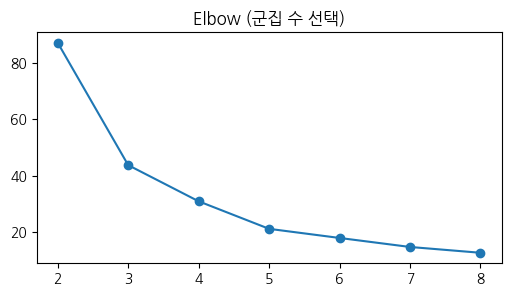

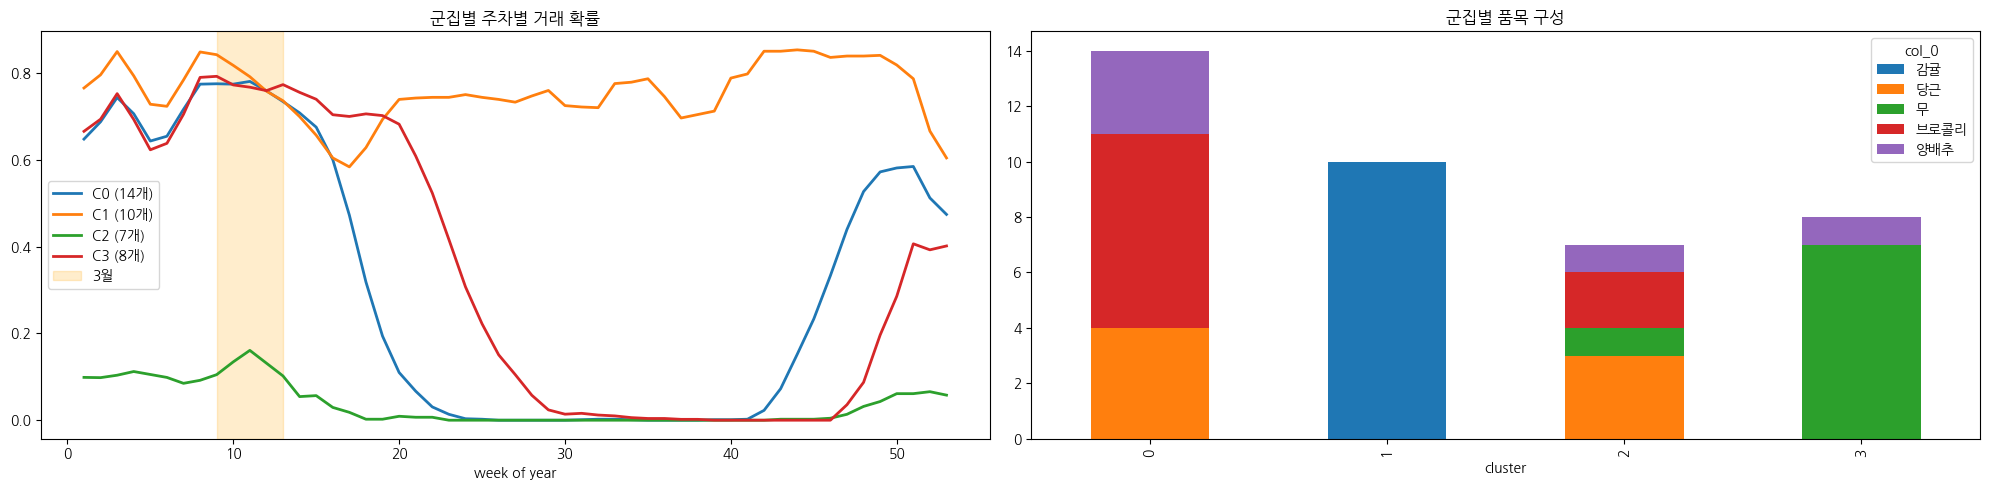

cluster
0    [BC_A_J, BC_A_S, BC_B_J, BC_C_J, BC_D_J, BC_E_...
1    [TG_A_J, TG_A_S, TG_B_J, TG_B_S, TG_C_J, TG_C_...
2    [BC_B_S, BC_C_S, CB_A_S, CR_B_J, CR_D_S, CR_E_...
3    [CB_F_J, RD_A_J, RD_A_S, RD_D_J, RD_D_S, RD_E_...


In [ ]:
from sklearn.cluster import KMeans

hist = T.loc[:'2022-02-28']
prof = hist.groupby(hist.index.isocalendar().week.values).mean().T   # 39 × 53
prof = prof.T.rolling(3, min_periods=1, center=True).mean().T   # 주차 방향으로 살짝 평활
inertia = [KMeans(k, n_init=20, random_state=0).fit(prof).inertia_ for k in range(2, 9)]
plt.figure(figsize=(6, 3)); plt.plot(range(2, 9), inertia, 'o-'); plt.title('Elbow (군집 수 선택)'); plt.show()

K = 4
km = KMeans(K, n_init=20, random_state=0).fit(prof)
cluster = pd.Series(km.labels_, index=SERIES, name='cluster')

fig, ax = plt.subplots(1, 2, figsize=(20, 5))
for k in range(K):
    ax[0].plot(prof.columns, prof[cluster == k].mean(), lw=2, label=f'C{k} ({(cluster == k).sum()}개)')
ax[0].axvspan(9, 13, color='orange', alpha=.2, label='3월'); ax[0].legend(); ax[0].set_title('군집별 주차별 거래 확률')
ax[0].set_xlabel('week of year')
pd.crosstab(cluster, item_of.map(ITEM_KR)).plot.bar(stacked=True, ax=ax[1], title='군집별 품목 구성')
plt.tight_layout(); plt.show()
print(cluster.groupby(cluster).apply(lambda x: list(x.index)).to_string())

### EDA 2 - 이상치 Hampel 필터

이상치 개수(시계열 상위 10):


,n
series,
TG_A_J,74
TG_B_J,69
TG_C_J,68
TG_D_S,67
TG_D_J,61
TG_E_J,59
TG_E_S,55
TG_B_S,54
CR_A_J,48


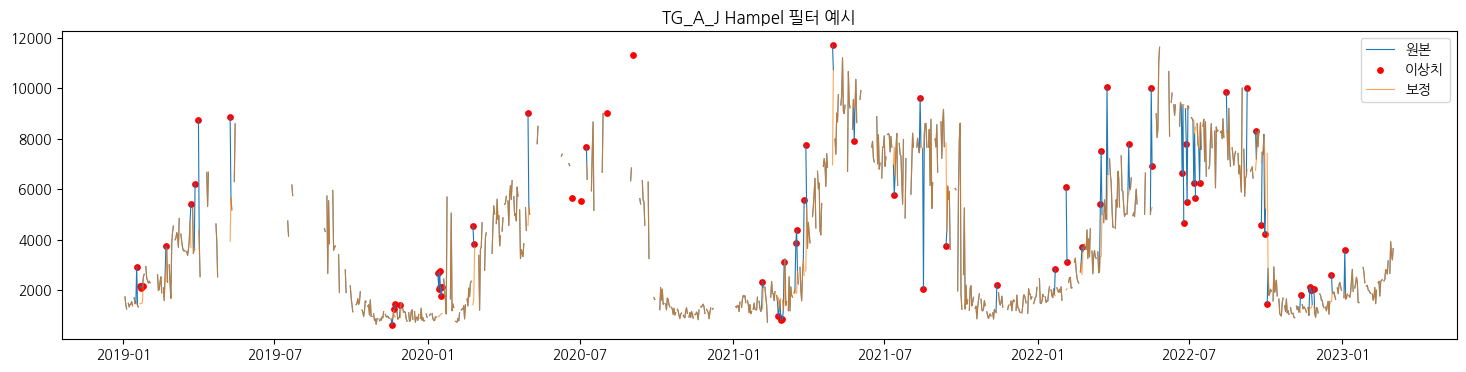

In [ ]:
Pnz = P.where(P > 0)
med = Pnz.rolling(15, min_periods=3).median()
mad = (Pnz - med).abs().rolling(15, min_periods=3).median()
is_out = (Pnz - med).abs() > 3 * 1.4826 * mad.replace(0, np.nan)
Pclean = Pnz.mask(is_out, med)

print('이상치 개수(시계열 상위 10):'); display(is_out.sum().sort_values(ascending=False).head(10).to_frame('n'))
s_ex = is_out.sum().idxmax()
fig, ax = plt.subplots(figsize=(18, 4))
ax.plot(Pnz[s_ex], lw=.8, label='원본'); ax.scatter(Pnz.index[is_out[s_ex]], Pnz[s_ex][is_out[s_ex]], c='r', s=15, label='이상치')
ax.plot(Pclean[s_ex], lw=.8, alpha=.7, label='보정'); ax.set_title(f'{s_ex} Hampel 필터 예시'); ax.legend(); plt.show()

### EDA 3  - 가격을 시계열 수준으로 나눠 보기 (정규화)

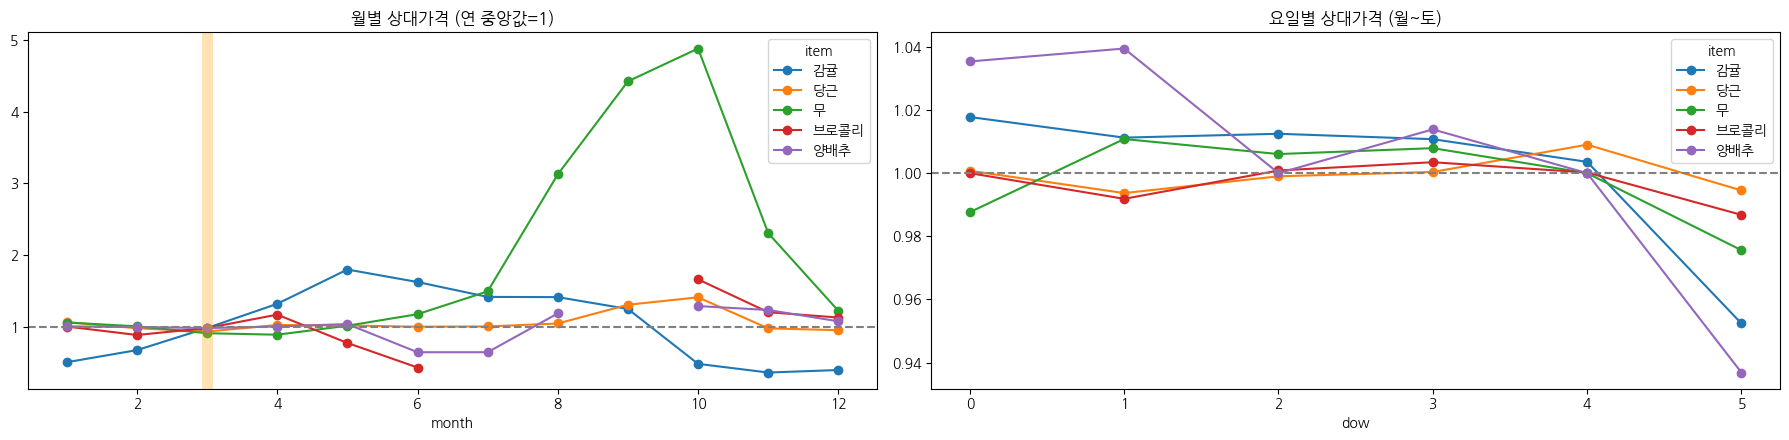

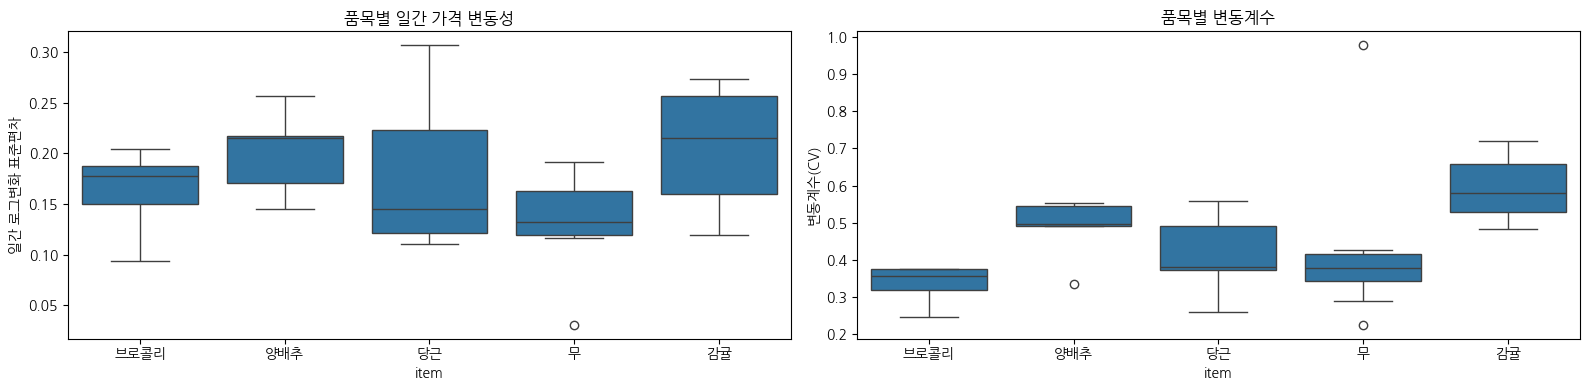

In [ ]:
yr_med = Pclean.groupby(Pclean.index.year).transform('median')
R = Pclean / yr_med   # 상대가격
rel = R.loc[:'2023-03-03'].stack().rename('rel').reset_index()
rel.columns = ['timestamp', 'series', 'rel']
rel['item'] = rel.series.str[:2].map(ITEM_KR)
rel['month'] = rel.timestamp.dt.month
rel['dow'] = rel.timestamp.dt.dayofweek

fig, ax = plt.subplots(1, 2, figsize=(18, 4.5))
rel.groupby(['month', 'item']).rel.median().unstack().plot(ax=ax[0], marker='o', title='월별 상대가격 (연 중앙값=1)')
ax[0].axhline(1, c='gray', ls='--'); ax[0].axvline(3, c='orange', lw=8, alpha=.3)
rel[rel.dow < 6].groupby(['dow', 'item']).rel.median().unstack().plot(ax=ax[1], marker='o', title='요일별 상대가격 (월~토)')
ax[1].axhline(1, c='gray', ls='--')
plt.tight_layout(); plt.show()

# %%
# 시계열별 변동성: 일간 변화율 분포 & 변동계수
chg = np.log(Pclean).diff()
vol = pd.DataFrame({'일간 로그변화 표준편차': chg.std(), '변동계수(CV)': Pnz.std() / Pnz.mean(), 'item': item_of.map(ITEM_KR)})
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
sns.boxplot(data=vol, x='item', y='일간 로그변화 표준편차', ax=ax[0]); ax[0].set_title('품목별 일간 가격 변동성')
sns.boxplot(data=vol, x='item', y='변동계수(CV)', ax=ax[1]); ax[1].set_title('품목별 변동계수')
plt.tight_layout(); plt.show()

### EDA 4 - 시계열 분해 (STL) 추세와 계절성의 비중

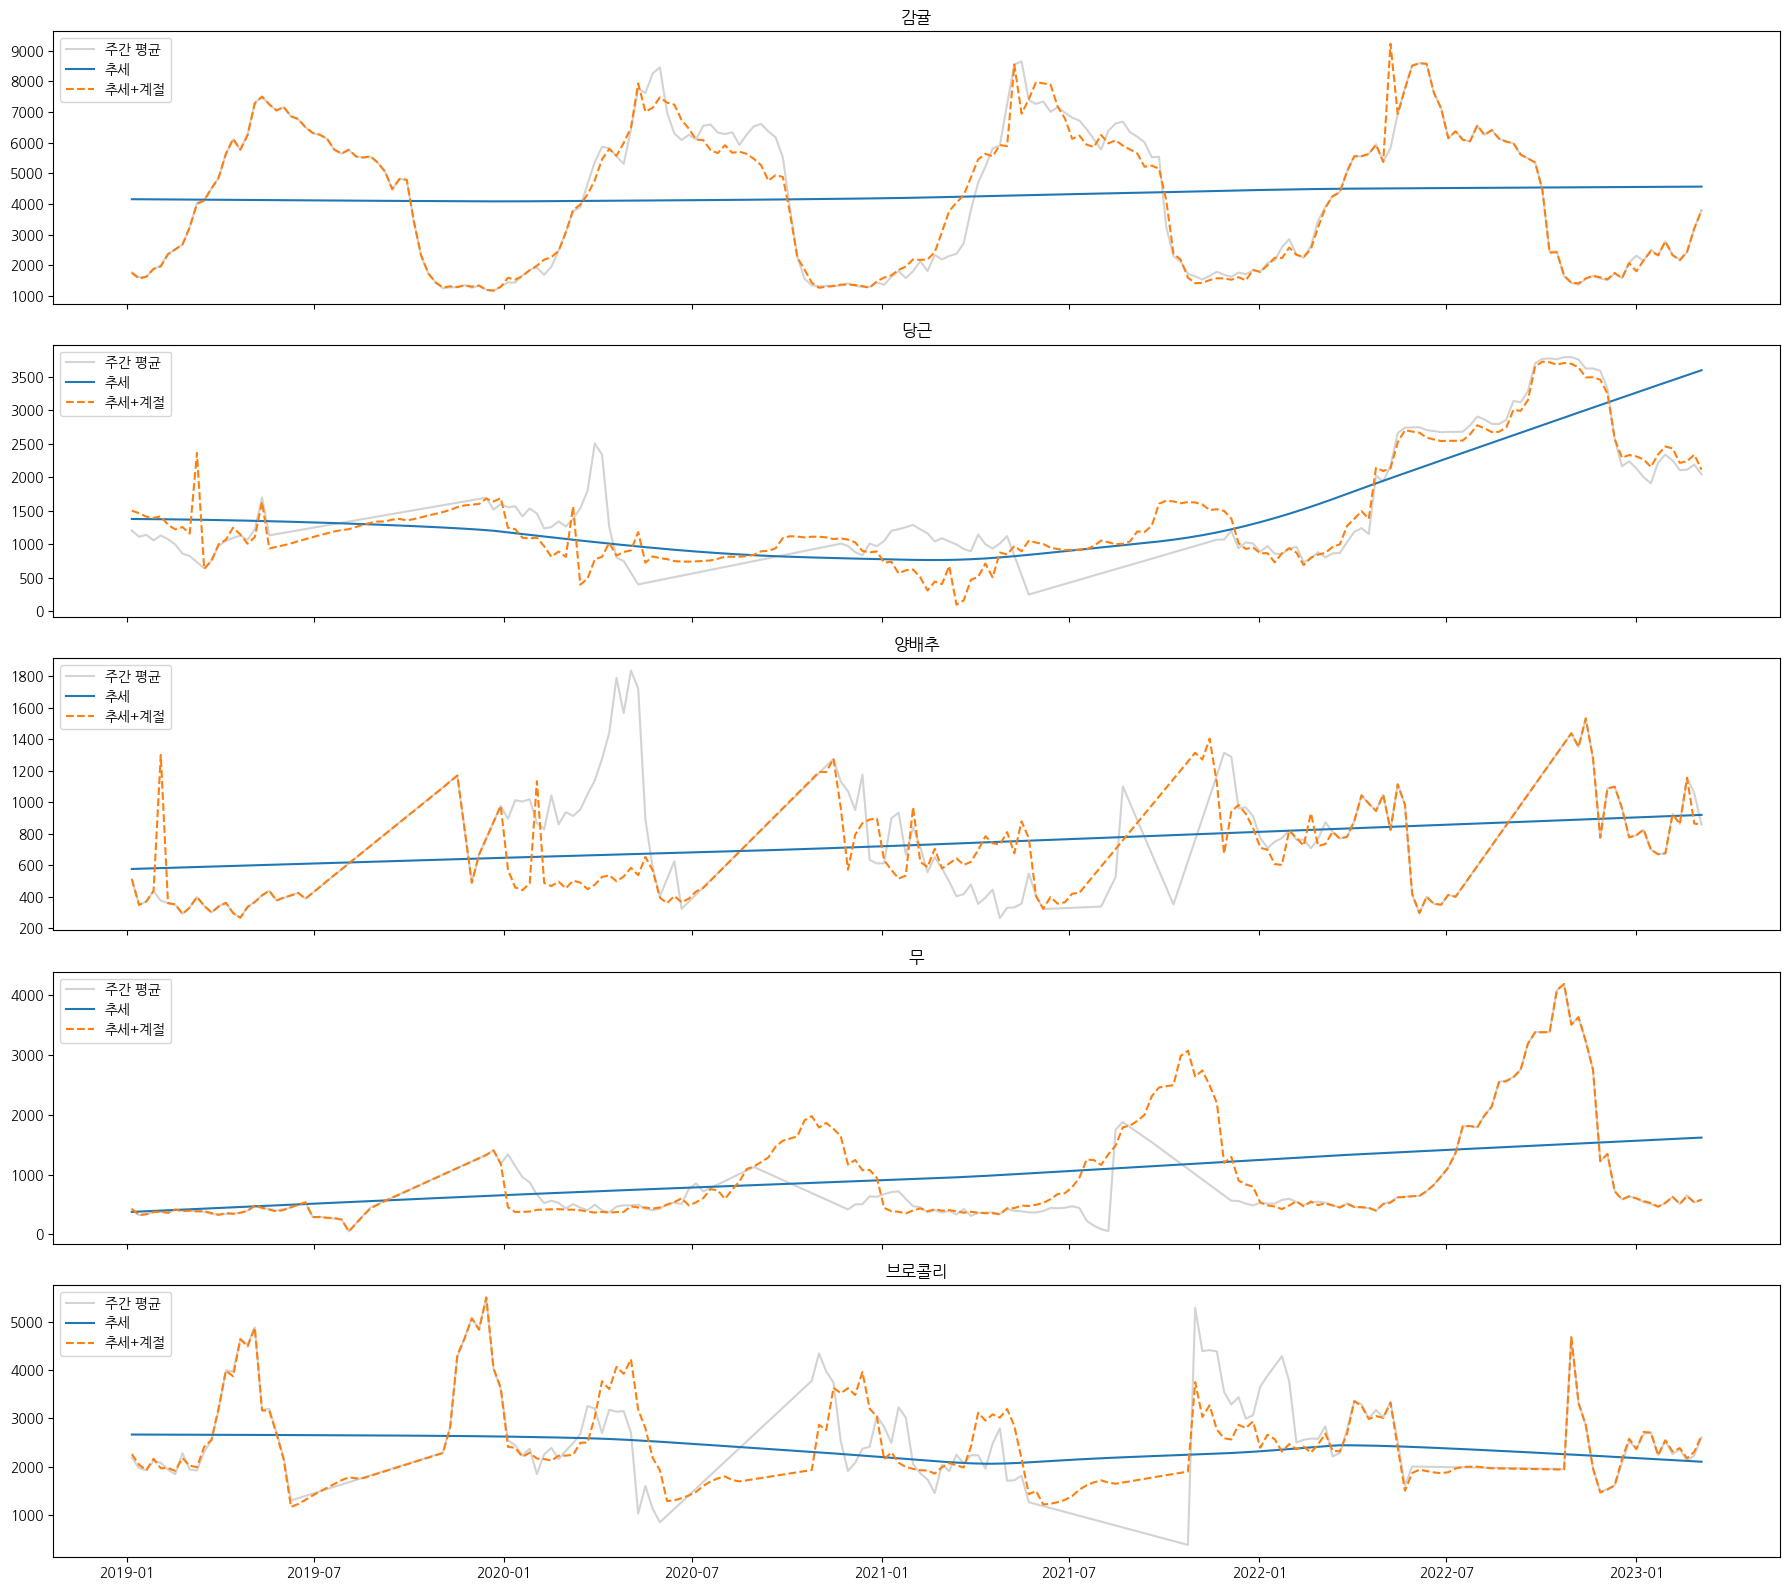

,추세 강도,계절성 강도
감귤,0.090,0.960
당근,0.790,0.430
양배추,0.010,0.220
무,0.330,0.580
브로콜리,0.120,0.550


In [ ]:
from statsmodels.tsa.seasonal import STL

fig, axes = plt.subplots(5, 1, figsize=(18, 16), sharex=True)
strength = {}
for ax, it in zip(axes, ITEMS):
    w = Pclean.loc[:'2023-03-03', item_of[item_of == it].index].mean(axis=1).resample('W').mean().interpolate().bfill()
    r = STL(w, period=52, robust=True).fit()
    strength[ITEM_KR[it]] = {'추세 강도': max(0, 1 - r.resid.var() / (r.trend + r.resid).var()),
                             '계절성 강도': max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var())}
    ax.plot(w, c='lightgray', label='주간 평균'); ax.plot(r.trend, label='추세'); ax.plot(r.trend + r.seasonal, ls='--', label='추세+계절')
    ax.set_title(ITEM_KR[it]); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()
display(pd.DataFrame(strength).T.round(2))

### EDA 5 - 공급 탄력성 (공급이 1% 늘면 가격은 몇 % 변하나)

In [ ]:
lp, ls_ = np.log(Pnz), np.log(S.where(S > 0))
rows = []
for it in ITEMS:
    cols = item_of[item_of == it].index
    for lag in [0, 7, 28]:
        x = (ls_[cols].shift(lag) - ls_[cols].mean()).stack()
        y = (lp[cols] - lp[cols].mean()).stack()
        xy = pd.concat([x, y], axis=1).dropna()
        rows.append([ITEM_KR[it], lag, np.polyfit(xy[0], xy[1], 1)[0], xy.corr().iloc[0, 1]])
elas = pd.DataFrame(rows, columns=['품목', '공급 lag(일)', '탄력성', '상관'])
display(elas.pivot(index='품목', columns='공급 lag(일)', values='탄력성').round(3))
print('→ 같은 날 공급 탄력성은 음수이지만, 28일 전 공급량의 설명력은 크게 줄어든다. 공급량은 보조 피처로만 사용.')

공급 lag(일),0,7,28
품목,,,
감귤,-0.333,-0.320,-0.258
당근,-0.174,-0.176,-0.182
무,-0.196,-0.193,-0.189
브로콜리,-0.085,-0.079,-0.028
양배추,-0.136,-0.121,-0.122


→ 같은 날 공급 탄력성은 음수이지만, 28일 전 공급량의 설명력은 크게 줄어든다. 공급량은 보조 피처로만 사용.


### EDA 6 - 예측 지평에 따른 불확실성

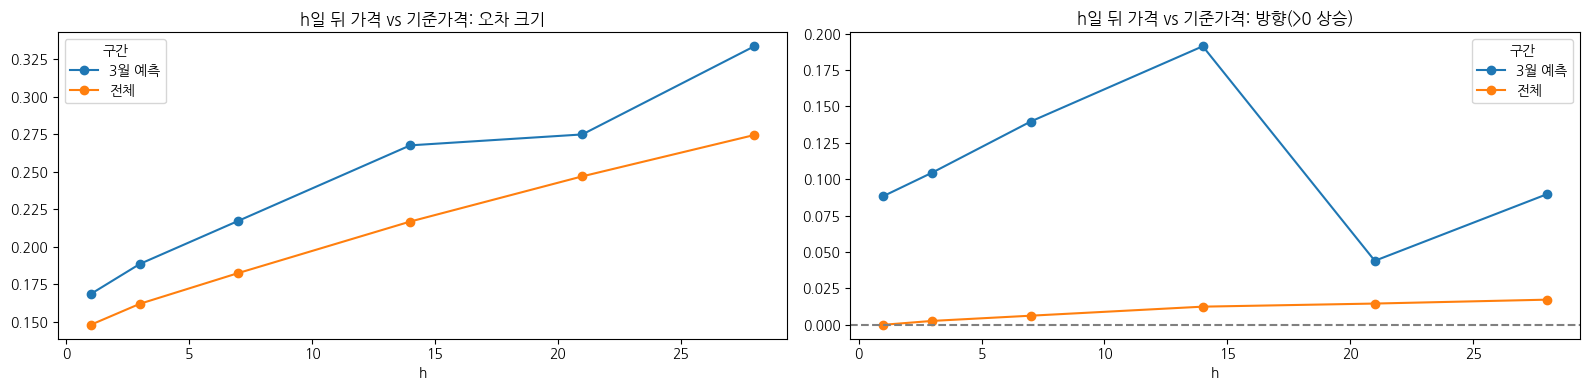

→ h가 커질수록 기준가격만으로는 오차가 커지고, 3월에는 가격이 기준가격보다 오르는 경향이 있다 → 변화율(Ratio)을 따로 학습


In [ ]:
level = Pclean.rolling(28, min_periods=3).median()
level = level.fillna(Pclean.rolling(91, min_periods=3).median()).fillna(Pclean.rolling(364, min_periods=1).median())
level = level.fillna(Pclean.expanding().median())                         # 1년 넘게 거래 없음 → 전체 과거 중앙값
level = level.fillna(level.T.groupby(item_of).transform('median').T)        # 거래 이력 자체가 없음 → 같은 품목 중앙값
rows = []
for h in [1, 3, 7, 14, 21, 28]:
    lr = np.log(Pnz.shift(-h) / level).loc[:'2023-02-01']
    for m in [None, 3]:
        v = lr if m is None else lr[lr.index.month == (m - 1 if h > 14 else m)]
        v = v.stack()
        rows.append([h, '전체' if m is None else '3월 예측', v.abs().median(), v.median()])
hz = pd.DataFrame(rows, columns=['h', '구간', '|log ratio| 중앙값', 'log ratio 중앙값'])
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
hz.pivot(index='h', columns='구간', values='|log ratio| 중앙값').plot(marker='o', ax=ax[0], title='h일 뒤 가격 vs 기준가격: 오차 크기')
hz.pivot(index='h', columns='구간', values='log ratio 중앙값').plot(marker='o', ax=ax[1], title='h일 뒤 가격 vs 기준가격: 방향(>0 상승)')
ax[1].axhline(0, c='gray', ls='--'); plt.tight_layout(); plt.show()
print('→ h가 커질수록 기준가격만으로는 오차가 커지고, 3월에는 가격이 기준가격보다 오르는 경향이 있다 → 변화율(Ratio)을 따로 학습')

### EDA 7 — 전년 대비 변화율 관점

In [ ]:
trade.columns = ['ym', 'trade_item', 'exp_w', 'exp_amt', 'imp_w', 'imp_amt', 'balance']
TRADE_MAP = {'감귤': 'TG', '당근': 'CR', '양배추': 'CB', '꽃양배추와 브로콜리(broccoli)': 'BC'}
tt = trade[trade.trade_item.isin(TRADE_MAP)].assign(item=lambda d: d.trade_item.map(TRADE_MAP))
tt['ym'] = pd.to_datetime(tt.ym)
tw = tt.pivot(index='ym', columns='item', values='imp_w').add(tt.pivot(index='ym', columns='item', values='exp_w'), fill_value=0)
pm = pd.DataFrame({it: Pnz[item_of[item_of == it].index].mean(axis=1).resample('MS').mean() for it in ITEMS})
yoy = pd.DataFrame({ITEM_KR[it]: [np.log(pm[it]).diff(12).corr(np.log1p(tw[it]).diff(12).shift(k)) for k in [0, 1, 2]]
                    for it in tw.columns}, index=['동월', '1개월 선행', '2개월 선행']).T
display(yoy.round(2))
print('→ 상관이 품목마다 부호와 크기가 일정하지 않음 → 모델 피처에서 제외 (과적합 방지)')

,동월,1개월 선행,2개월 선행
브로콜리,0.210,-0.150,-0.250
양배추,0.700,0.540,0.400
당근,0.320,0.180,0.390
감귤,-0.280,-0.020,0.030


→ 상관이 품목마다 부호와 크기가 일정하지 않음 → 모델 피처에서 제외 (과적합 방지)


# 4. 전처리 · 피처 생성

In [ ]:
nz_mean7 = Pclean.rolling(7, min_periods=1).mean()
nz_mean28 = Pclean.rolling(28, min_periods=1).mean()
nz_std28 = Pclean.rolling(28, min_periods=3).std()
last_price = Pclean.ffill()
trade_rate28 = T.rolling(28, min_periods=1).mean()
trade_rate7 = T.rolling(7, min_periods=1).mean()
# 마지막 거래 후 경과일
idx = np.arange(len(dates))[:, None].repeat(len(SERIES), 1)
last_tr = pd.DataFrame(np.where(T.values == 1, idx, np.nan), index=dates, columns=SERIES).ffill()
days_since = idx - last_tr.values
sup_mean28 = S.where(S > 0).rolling(28, min_periods=1).mean()
# 작년 같은 날 기준 ±3일 거래가격 / 거래확률 (centered)
c_price7 = Pclean.rolling(7, center=True, min_periods=1).mean()
c_trade7 = T.rolling(7, center=True, min_periods=1).mean()
# 품목 공통: 품목 시계열들의 (최근7일 / 기준가격) 평균
mom = (nz_mean7 / level)
item_mom = mom.T.groupby(item_of).transform('mean').T

state = {k: v.values for k, v in dict(level=level, nz_mean7=nz_mean7, nz_mean28=nz_mean28, nz_std28=nz_std28,
                                     last_price=last_price, trade_rate28=trade_rate28, trade_rate7=trade_rate7,
                                     sup_mean28=sup_mean28, c_price7=c_price7, c_trade7=c_trade7,
                                     item_mom=item_mom).items()}
state['days_since'] = days_since
Tv, Pv = T.values, P.values
print({k: v.shape for k, v in state.items()})

{'level': (1551, 39), 'nz_mean7': (1551, 39), 'nz_mean28': (1551, 39), 'nz_std28': (1551, 39), 'last_price': (1551, 39), 'trade_rate28': (1551, 39), 'trade_rate7': (1551, 39), 'sup_mean28': (1551, 39), 'c_price7': (1551, 39), 'c_trade7': (1551, 39), 'item_mom': (1551, 39), 'days_since': (1551, 39)}


학습 데이터: (307944, 31) | 예측 시점 수: 282


,origin,target,series,h,item,corp,loc,cluster,s_code,t_dow,t_month,t_doy,o_dow,level_log,mom7,mom28,cv28,last_ratio,trade_rate7,trade_rate28,days_since,item_mom,sup_log,dow_trade4,ly_ratio,ly_trade,ly2_ratio,y,trade,log_ratio,lev
252020,2022-07-13,2022-08-03,TG_A_S,21,4,0,1,1,30,2,8,215,2,8.717,0.943,1.008,0.119,0.890,0.857,0.857,0.000,0.955,8.349,1.000,0.913,0.714,1.060,"6,251.000",1.000,0.023,"6,108.000"
112952,2021-02-20,2021-02-21,CR_D_J,1,2,3,0,0,17,6,2,52,5,7.150,0.855,0.963,0.124,0.495,0.857,0.714,0.000,0.848,10.945,0.000,0.954,0.857,0.875,0.000,0.000,NaN,"1,274.000"
263889,2022-08-26,2022-09-13,RD_D_S,18,3,3,1,3,25,1,9,256,4,6.735,NaN,NaN,NaN,0.892,0.000,0.000,70.000,1.172,NaN,0.000,NaN,0.000,NaN,0.000,0.000,NaN,841.000
100743,2021-01-07,2021-02-04,CB_A_J,28,1,0,0,0,9,3,2,35,3,6.655,1.085,1.085,0.230,1.064,0.571,0.143,0.000,1.127,9.028,0.250,2.015,0.429,NaN,0.000,0.000,NaN,776.500
136487,2021-05-15,2021-05-31,TG_E_S,16,4,4,1,1,38,0,5,151,5,8.835,1.369,1.008,0.442,1.146,0.714,0.750,0.000,1.134,6.562,1.000,0.933,0.857,0.957,"6,032.000",1.000,-0.130,"6,871.000"


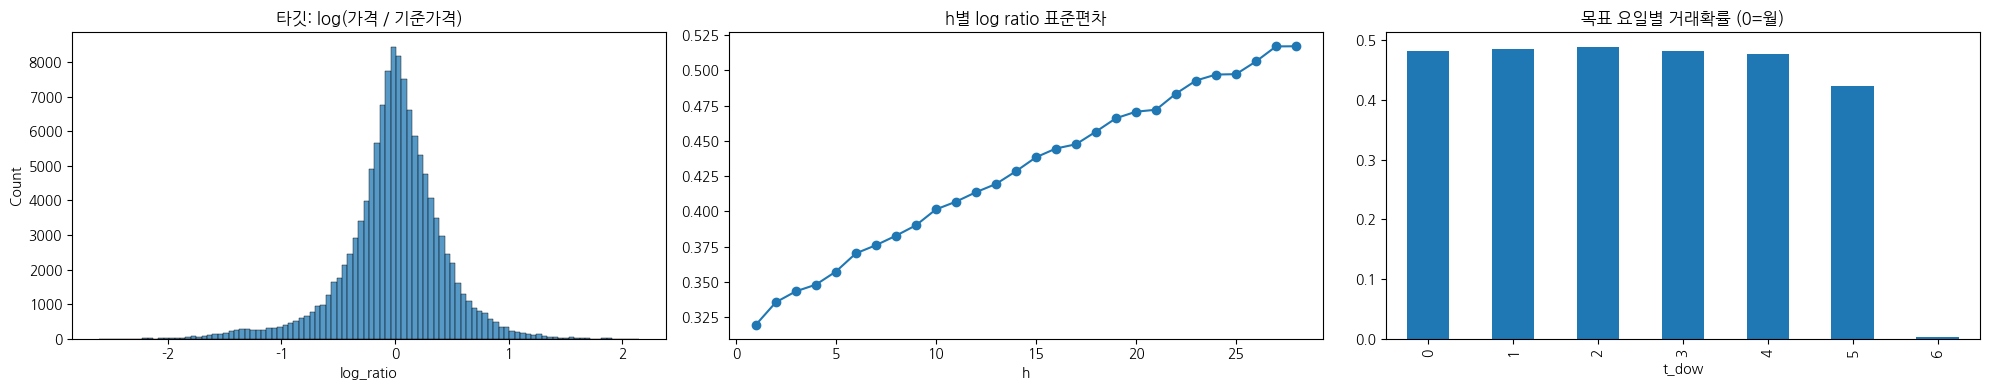

In [ ]:
s_code = np.arange(len(SERIES))
item_code = pd.Series(item_of.values).astype('category').cat.codes.values
clus = cluster.reindex(SERIES).values
corp_code = pd.Series([s[3] for s in SERIES]).astype('category').cat.codes.values
loc_code = (pd.Series([s[5] for s in SERIES]) == 'S').astype(int).values
date_pos = {d: i for i, d in enumerate(dates)}

def make_rows(origin_idx):
    o = np.repeat(origin_idx, len(SERIES) * H)
    s = np.tile(np.repeat(s_code, H), len(origin_idx))
    h = np.tile(np.arange(1, H + 1), len(origin_idx) * len(SERIES))
    t = o + h
    tdate = dates[t]
    lev = state['level'][o, s]
    f = pd.DataFrame({
        'origin': dates[o], 'target': tdate, 'series': np.array(SERIES)[s], 'h': h,
        'item': item_code[s], 'corp': corp_code[s], 'loc': loc_code[s], 'cluster': clus[s], 's_code': s,
        't_dow': tdate.dayofweek, 't_month': tdate.month, 't_doy': tdate.dayofyear, 'o_dow': dates[o].dayofweek,
        'level_log': np.log(lev),
        'mom7': state['nz_mean7'][o, s] / lev, 'mom28': state['nz_mean28'][o, s] / lev,
        'cv28': state['nz_std28'][o, s] / lev, 'last_ratio': state['last_price'][o, s] / lev,
        'trade_rate7': state['trade_rate7'][o, s], 'trade_rate28': state['trade_rate28'][o, s],
        'days_since': state['days_since'][o, s], 'item_mom': state['item_mom'][o, s],
        'sup_log': np.log(state['sup_mean28'][o, s]),
    })
    # 목표 요일과 같은 요일의, 예측 시점 이전 최근 4주 거래 여부 평균
    m0 = np.ceil(h / 7).astype(int)
    f['dow_trade4'] = np.nanmean(np.stack([Tv[t - 7 * (m0 + k), s] for k in range(4)]), axis=0)
    # 작년: 목표일(t-364) 주변 가격 / 작년 예측시점 기준가격 → 작년의 같은 h 변화율
    ly_lev = state['level'][o - 364, s]
    f['ly_ratio'] = state['c_price7'][t - 364, s] / ly_lev
    f['ly_trade'] = state['c_trade7'][t - 364, s]
    f['ly2_ratio'] = np.where(o - 728 >= 0, state['c_price7'][np.maximum(t - 728, 0), s] / state['level'][np.maximum(o - 728, 0), s], np.nan)
    # 타깃
    y = Pv[t, s]
    f['y'] = y
    f['trade'] = (y > 0).astype(float)
    f['log_ratio'] = np.where(y > 0, np.log(np.where(y > 0, y, 1) / lev), np.nan)
    f['lev'] = lev
    return f

FEATS = ['h', 'item', 'corp', 'loc', 'cluster', 's_code', 't_dow', 't_month', 't_doy', 'o_dow', 'level_log',
         'mom7', 'mom28', 'cv28', 'last_ratio', 'trade_rate7', 'trade_rate28', 'days_since', 'item_mom', 'sup_log',
         'dow_trade4', 'ly_ratio', 'ly_trade', 'ly2_ratio']

first_origin = date_pos[pd.Timestamp('2020-01-05')]           # 작년 피처 확보 이후
last_known = date_pos[pd.Timestamp('2023-03-03')]
all_origins = np.arange(first_origin, last_known - H + 1, 4)
DS = make_rows(all_origins)
print('학습 데이터:', DS.shape, '| 예측 시점 수:', len(all_origins))
display(DS.sample(5, random_state=0))
fig, ax = plt.subplots(1, 3, figsize=(20, 4))
sns.histplot(DS.log_ratio.dropna(), bins=100, ax=ax[0]); ax[0].set_title('타깃: log(가격 / 기준가격)')
DS.groupby('h').log_ratio.std().plot(ax=ax[1], marker='o', title='h별 log ratio 표준편차')
DS.groupby('t_dow').trade.mean().plot.bar(ax=ax[2], title='목표 요일별 거래확률 (0=월)')
plt.tight_layout(); plt.show()

## 📌 요약 (EDA + 전처리)

**핵심 아이디어**: 가격을 그대로 예측하지 않고 세 부분으로 나눠서 예측한다.
> **가격 = 거래 여부 × 기준가격 × 변화율**
> - 기준가격: 예측 시점 직전 28일 거래가격의 중앙값
> - 변화율: 기준가격 대비 h일 뒤 가격이 몇 배인지

**EDA에서 알게 된 것**
1. 전체의 약 60%가 가격 0 = 거래가 없는 날 (일요일은 100% 0). 시계열마다 출하 시즌과 쉬는 요일이 다르다.
2. 출하 시즌 패턴으로 묶으면 39개 시계열이 4개 유형으로 나뉜다. 3월에 거의 거래가 없는 시계열 그룹도 따로 있다.
3. 감귤은 계절성이 매우 강하고(0.96), 당근은 추세가 강하다(0.79).
4. 공급이 늘면 가격이 내려간다. 감귤이 가장 민감하다(공급 +1% → 가격 약 -0.33%).
5. 예측 거리(h)가 멀수록 기준가격만으로는 오차가 커지고, 3월에는 가격이 오르는 경향이 있다.
6. 수출입 데이터는 품목마다 상관의 방향이 들쭉날쭉해서 피처에서 뺐다.

**전처리**
- 튀는 가격은 Hampel 필터로 보정 (피처 계산에만 쓰고, 정답 값은 그대로)
- 학습 데이터를 **(예측 시점 × 시계열 × 1~28일 뒤)** 단위로 새로 만듦 → 30만 7944행, 피처 24개
- 주요 피처: 기준가격, 최근 추세, 요일별 최근 거래확률, 작년 같은 시기 변화율, 출하 군집
- 모든 피처는 예측 시점까지의 데이터만 사용 (미래 정보 누수 없음)

**모델링 계획**
- 거래 여부 분류 모델 + 변화율 회귀 모델
- 최종 예측 = 거래 확률 × (기준가격 × 변화율)

# 5. 피처 확장

v2 베이스라인 피처 24개에 아래 5개를 추가해 실험한다. 모두 **예측 시점 이전 정보만** 사용한다
(작년 값은 t−364일 ≤ 예측 시점).

| 피처 | 의미 | 기대 효과 |
|---|---|---|
| `yoy_level` | log(현재 기준가격 / 1년 전 기준가격) | 올해 가격 수준이 작년보다 높은지 → 작년 변화율을 얼마나 믿을지 |
| `mom_trend` | log(최근 7일 평균 / 최근 28일 평균) | 단기 추세 방향 |
| `ly_trade_exact` | 작년 같은 요일·같은 날(t−364)의 거래 여부 | 시즌 시작/종료 시점 포착 |
| `item_ly_ratio` | 같은 품목 시계열들의 작년 변화율 평균 | 시계열 하나보다 덜 시끄러운 작년 패턴 |
| `item_ly_trade` | 같은 품목 시계열들의 작년 거래 비율 평균 | 품목 전체의 출하 시즌 |

In [ ]:
NEW_FEATS = ['yoy_level', 'mom_trend', 'ly_trade_exact', 'item_ly_ratio', 'item_ly_trade']

def add_features(f):
    f = f.copy()
    o = dates.get_indexer(f['origin'])
    t = dates.get_indexer(f['target'])
    s = f['s_code'].values
    f['yoy_level'] = np.log(f['lev'].values / state['level'][o - 364, s])
    f['mom_trend'] = np.log(f['mom7'] / f['mom28'])
    f['ly_trade_exact'] = Tv[t - 364, s]
    g = f.groupby(['origin', 'item', 'h'])
    f['item_ly_ratio'] = g['ly_ratio'].transform('mean')
    f['item_ly_trade'] = g['ly_trade'].transform('mean')
    f[NEW_FEATS] = f[NEW_FEATS].replace([np.inf, -np.inf], np.nan)
    return f

def make_rows_x(origin_idx):
    return add_features(make_rows(origin_idx))

DS = add_features(DS)
assert (dates.get_indexer(DS['target']) - 364 <= dates.get_indexer(DS['origin'])).all()   # 작년 값은 예측 시점 이전
display(DS[NEW_FEATS].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
yoy_level,"307,944.000",0.069,0.458,-1.937,-0.193,0.060,0.299,2.153
mom_trend,"173,376.000",-0.022,0.197,-2.472,-0.084,0.000,0.077,0.825
ly_trade_exact,"307,944.000",0.395,0.489,0.000,0.000,0.000,1.000,1.000
item_ly_ratio,"217,119.000",1.111,0.494,0.109,0.877,1.029,1.248,4.369
item_ly_trade,"307,944.000",0.395,0.327,0.000,0.000,0.460,0.696,1.000


# 6. 검증 설계

test와 똑같이 **예측 시점 1곳에서 1~28일 뒤**를 예측한다. 각 검증에서는 **정답 날짜가 예측 시점 이전인 행만** 학습에 쓴다.

| fold | 예측 시점 | 목표 기간 | 가중치 |
|---|---|---|---|
| 21-03 | 2021-03-03 | 3/4 ~ 3/31 | 2 (test와 같은 시즌) |
| 22-03 | 2022-03-03 | 3/4 ~ 3/31 | 2 |
| 23-01 | 2023-01-05 | 1/6 ~ 2/2 | 1 (최신 가격 흐름) |
| 23-02 | 2023-02-02 | 2/3 ~ 3/2 | 1 |

- **목표 점수** = fold별 RMSE의 가중 평균 (3월 fold 가중치 2)
- Public 점수(3/4~3/17)를 흉내 낸 **h ≤ 14 RMSE**도 함께 본다
- 출하 군집은 2022-02-28까지의 데이터로 만들었기 때문에 21-03 fold에는 약간의 정보가 섞여 있다(점수가 다소 낙관적일 수 있음)

**채택 규칙** (검증 데이터에 과적합하지 않기 위해)
- 모델 실험: 목표 점수가 좋아지고, 4개 fold 중 **2개 이상**에서 좋아지면 채택
- 후처리: 여러 값 중 최선을 고르는 것이라 더 엄격하게, 4개 fold 중 **3개 이상**에서 좋아져야 채택

In [ ]:
VALID = {'21-03': '2021-03-03', '22-03': '2022-03-03', '23-01': '2023-01-05', '23-02': '2023-02-02'}
FOLD_W = {'21-03': 2, '22-03': 2, '23-01': 1, '23-02': 1}
MARCH = ['21-03', '22-03']
META = ['origin', 'target', 'series', 'h', 'item', 't_dow', 'y', 'trade', 'lev', 'log_ratio', 'ly_ratio']

def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y, float) - np.asarray(p, float)) ** 2)))

def baseline_b3(va, origin):
    # 계절 평균: 과거 같은 월·같은 요일의 가격 평균(0 포함), 예측 시점까지의 데이터만 사용
    hist = P.loc[:origin]
    tab = hist.groupby([hist.index.month, hist.index.dayofweek]).mean().stack()
    idx = pd.MultiIndex.from_arrays([va['target'].dt.month, va['t_dow'], va['series']])
    return np.nan_to_num(tab.reindex(idx).values)

FOLDS = {}
for k, v in VALID.items():
    o = date_pos[pd.Timestamp(v)]
    tr_mask = (DS['target'] <= dates[o]).values
    va = make_rows_x(np.array([o]))
    va['b3'] = baseline_b3(va, v)
    FOLDS[k] = (tr_mask, va)
    print(f'[{k}] 학습 {tr_mask.sum():,}행 | 검증 {len(va):,}행 ({va.target.min().date()} ~ {va.target.max().date()})')

def scores(oof, col='pred'):
    # fold별 RMSE + 3월 평균 + 가중 목표 + Public 흉내(h≤14)
    r = {k: rmse(d.y, d[col]) for k, d in oof.groupby('fold')}
    out = dict(r)
    out['3월 평균'] = np.mean([r[k] for k in MARCH])
    out['목표(가중)'] = sum(r[k] * FOLD_W[k] for k in r) / sum(FOLD_W.values())
    pub = oof[oof.h <= 14]
    out['h≤14 (가중)'] = sum(rmse(d.y, d[col]) * FOLD_W[k] for k, d in pub.groupby('fold')) / sum(FOLD_W.values())
    return out

def adopt(new, old, min_wins):
    wins = sum(new[k] < old[k] for k in VALID)
    return (new['목표(가중)'] < old['목표(가중)']) and wins >= min_wins, wins

[21-03] 학습 112,203행 | 검증 1,092행 (2021-03-04 ~ 2021-03-31)
[22-03] 학습 211,848행 | 검증 1,092행 (2022-03-04 ~ 2022-03-31)
[23-01] 학습 295,932행 | 검증 1,092행 (2023-01-06 ~ 2023-02-02)
[23-02] 학습 303,576행 | 검증 1,092행 (2023-02-03 ~ 2023-03-02)


# 7. 모델 정의

| 모델 | 타깃 | 손실 | 가중치 |
|---|---|---|---|
| 분류 | 거래 여부 | binary | 시즌(2~4월) × 최근성 |
| 회귀 A | log(가격/기준가격) | huber | 시즌 × 최근성 |
| 회귀 B | 가격/기준가격 | MSE | 기준가격² × 최근성 → 원/kg 단위 RMSE를 직접 줄임 |

- 회귀 A는 가격을 낮게, B는 높게 예측하는 경향이 있어 섞으면 서로 상쇄된다 (v2 분석 결과)
- 설정(`cfg`)으로 피처 목록 · 시즌 가중치 · 최근성 가중치(반감기)를 바꿔 가며 실험한다

In [ ]:
BASE_PARAMS = dict(n_estimators=400, learning_rate=0.05, num_leaves=63, min_child_samples=50,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                   deterministic=True, force_row_wise=True, verbose=-1)

CFG_V2 = dict(feats=list(FEATS), season_k=2.0, half_life=None)   # v2 베이스라인 설정

def weights(d, cfg, season=True):
    w = np.ones(len(d))
    if season and cfg['season_k'] != 1:
        w *= np.where(d['t_month'].isin([2, 3, 4]), cfg['season_k'], 1.0)
    if cfg['half_life']:
        age = (d['origin'].max() - d['origin']).dt.days.values
        w *= 0.5 ** (age / cfg['half_life'])
    return w

def fit_models(tr, cfg, seed=0):
    F = cfg['feats']
    pos = tr[(tr.trade == 1) & tr.log_ratio.notna()]
    p = dict(BASE_PARAMS, random_state=seed)
    clf = lgb.LGBMClassifier(**p, objective='binary').fit(tr[F], tr.trade, sample_weight=weights(tr, cfg))
    reg_a = lgb.LGBMRegressor(**p, objective='huber', alpha=0.3).fit(
        pos[F], pos.log_ratio, sample_weight=weights(pos, cfg))
    reg_b = lgb.LGBMRegressor(**p, objective='regression').fit(
        pos[F], np.exp(pos.log_ratio), sample_weight=pos.lev.values ** 2 * weights(pos, cfg, season=False))
    return dict(clf=clf, reg_a=reg_a, reg_b=reg_b)

def predict_parts(m, d, cfg):
    X, L = d[cfg['feats']], d['lev'].values
    return pd.DataFrame({'prob': m['clf'].predict_proba(X)[:, 1],
                         'price_A': L * np.exp(m['reg_a'].predict(X)),
                         'price_B': L * np.clip(m['reg_b'].predict(X), 0, None)}, index=d.index)

def run_cv(cfg, label=''):
    t0, out = time.time(), []
    for k, (tr_mask, va) in FOLDS.items():
        m = fit_models(DS[tr_mask], cfg)
        out.append(pd.concat([va[META + ['b3']], predict_parts(m, va, cfg)], axis=1).assign(fold=k))
    oof = pd.concat(out, ignore_index=True)
    oof['pred'] = oof.prob * (oof.price_A + oof.price_B) / 2          # v2 결합 방식 (후처리 전)
    print(f'{label} 완료 ({time.time() - t0:.0f}초)')
    return oof

# 8. 성능 향상 실험

v2를 기준점으로, 실험을 **하나씩 순서대로** 추가한다. 채택되면 다음 실험은 그 위에서 진행한다.

| 실험 | 내용 | 근거 |
|---|---|---|
| E1 | 신규 피처 5개 추가 | 작년 패턴을 덜 시끄럽게, 올해 가격 수준 반영 |
| E2 | 최근 데이터 가중치 (반감기 1년) | 가격 수준·출하 패턴이 해마다 바뀜 |
| E3 | 시즌 가중치 2 → 3 | 3월 근처 패턴을 더 강조 |
| E4 | 트리 400 → 800, 학습률 0.05 → 0.03 | 더 천천히, 더 많이 학습 |

비교 기준으로 단순 계절 평균 **B3**(과거 같은 월·요일 평균)도 함께 표시한다.

In [ ]:
log_rows = []
b3_oof = pd.concat([va.assign(fold=k, pred=va.b3) for k, (_, va) in FOLDS.items()])
b3_score = scores(b3_oof)
log_rows.append({'실험': 'B3 계절 평균 (참고)', **b3_score, '채택': '-'})

best_cfg, best_params = dict(CFG_V2), dict(BASE_PARAMS)
best_oof = run_cv(best_cfg, 'E0 v2 재현')
best_score = scores(best_oof)
log_rows.append({'실험': 'E0 v2 재현 (기준)', **best_score, '채택': '기준'})
OOF_V2 = best_oof.copy()

EXPERIMENTS = [
    ('E1 신규 피처 추가',        dict(feats=list(FEATS) + NEW_FEATS), None),
    ('E2 최근 가중치(반감기 1년)', dict(half_life=365),                 None),
    ('E3 시즌 가중치 3',          dict(season_k=3.0),                   None),
    ('E4 트리 800 / lr 0.03',     {},                                   dict(n_estimators=800, learning_rate=0.03)),
]
for name, cfg_change, param_change in EXPERIMENTS:
    cand_cfg = {**best_cfg, **cfg_change}
    BASE_PARAMS = {**best_params, **(param_change or {})}
    oof = run_cv(cand_cfg, name)
    sc = scores(oof)
    ok, wins = adopt(sc, best_score, min_wins=2)
    log_rows.append({'실험': name, **sc, '채택': f"{'✅' if ok else '❌'} ({wins}/4 fold 개선)"})
    if ok:
        best_cfg, best_params, best_oof, best_score = cand_cfg, dict(BASE_PARAMS), oof, sc
    BASE_PARAMS = dict(best_params)

EXP_LOG = pd.DataFrame(log_rows).set_index('실험')
display(EXP_LOG.round(1))
print('최종 모델 설정:', {k: (f'{len(v)}개 피처' if k == 'feats' else v) for k, v in best_cfg.items()},
      '| 트리', best_params['n_estimators'], '/ lr', best_params['learning_rate'])

E0 v2 재현 완료 (121초)
E1 신규 피처 추가 완료 (134초)
E2 최근 가중치(반감기 1년) 완료 (118초)
E3 시즌 가중치 3 완료 (118초)
E4 트리 800 / lr 0.03 완료 (224초)


,21-03,22-03,23-01,23-02,3월 평균,목표(가중),h≤14 (가중),채택
실험,,,,,,,,
B3 계절 평균 (참고),900.800,989.700,815.100,760.100,945.300,892.700,740.900,-
E0 v2 재현 (기준),729.800,984.200,852.800,720.200,857.000,833.500,624.800,기준
E1 신규 피처 추가,718.100,989.900,873.300,764.100,854.000,842.200,644.900,❌ (1/4 fold 개선)
E2 최근 가중치(반감기 1년),736.000,988.100,922.900,716.900,862.100,848.000,623.900,❌ (1/4 fold 개선)
E3 시즌 가중치 3,714.800,982.300,858.300,750.000,848.500,833.700,622.700,❌ (2/4 fold 개선)
E4 트리 800 / lr 0.03,730.700,"1,006.500",853.100,748.200,868.600,846.000,627.500,❌ (0/4 fold 개선)


최종 모델 설정: {'feats': '24개 피처', 'season_k': 2.0, 'half_life': None} | 트리 400 / lr 0.05


# 9. 후처리 실험

모델을 다시 학습하지 않고, 검증 예측값(거래 확률, 회귀 A·B 가격, B3)을 조합하는 방식만 바꿔 본다.
아래 순서대로 하나씩 최선값을 찾고, **4개 fold 중 3개 이상**에서 좋아질 때만 채택한다.
한 설정이 바뀌면 다른 설정의 최적값도 달라질 수 있어 전체를 **2바퀴** 반복한다.

| 순서 | 후처리 | 후보 값 | 이유 |
|---|---|---|---|
| 1 | 일요일 0 `sunday0` | 끔 / 켬 | 일요일은 100% 거래 없음 |
| 2 | B3 섞기 `w_b3` | 0 ~ 0.7 | 서로 다른 방식의 예측을 섞어 오차 상쇄 |
| 3 | B3 섞기 (h>14 따로) `w_b3_long` | 없음 / 0 ~ 0.7 | 먼 날짜일수록 모델 정보가 약해지므로 비중을 따로 둘지 확인 |
| 4 | 회귀 A 비중 `w_A` | 0 ~ 1 | 낮게 예측하는 A와 높게 예측하는 B의 최적 비율 |
| 5 | 낮은 확률 → 0 `lo` | 0 ~ 0.3 | 거래 가능성이 낮으면 0이 더 정확한 경우 |
| 6 | 높은 확률 → 1 `hi` | 1 ~ 0.7 | 거래가 거의 확실하면 가격을 깎지 않기 |
| 7 | 가격 배율 `scale` | 0.90 ~ 1.10 | 전체적인 과대/과소 예측 보정 |

**결과**: 일요일 0, B3 섞기 0.4 채택 (목표 점수 833.5 → 795.5, 4개 fold 모두 개선).
가격 배율 0.97도 규칙상 채택됐지만 개선이 0.3점(잡음 수준)이고 최근 fold(23-02)에서는 나빠져서 1.0으로 되돌렸다.

In [ ]:
PP_DEFAULT = dict(sunday0=False, w_A=0.5, lo=0.0, hi=1.0, scale=1.0, w_b3=0.0, w_b3_long=None)

def postprocess(d, pp):
    p = d['prob'].values.copy()
    p = np.where(p < pp['lo'], 0.0, p)
    p = np.where(p > pp['hi'], 1.0, p)
    price = pp['scale'] * (pp['w_A'] * d['price_A'].values + (1 - pp['w_A']) * d['price_B'].values)
    # B3 비중: h≤14(Public 구간)와 h>14를 따로 둘 수 있음 (w_b3_long=None이면 같은 값)
    w_long = pp['w_b3'] if pp['w_b3_long'] is None else pp['w_b3_long']
    w = np.where(d['h'].values <= 14, pp['w_b3'], w_long)
    pred = (1 - w) * p * price + w * d['b3'].values
    if pp['sunday0']:
        pred = np.where(d['t_dow'].values == 6, 0.0, pred)
    return np.clip(np.nan_to_num(pred), 0, None)

B3_W = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
GRID = [('일요일 0',              'sunday0',   [False, True]),
        ('B3 섞기',               'w_b3',      B3_W),
        ('B3 섞기 (h>14 따로)',   'w_b3_long', [None] + B3_W),
        ('회귀 A 비중',           'w_A',       [0.0, 0.25, 0.5, 0.75, 1.0]),
        ('낮은 확률 → 0',         'lo',        [0.0, 0.05, 0.1, 0.2, 0.3]),
        ('높은 확률 → 1',         'hi',        [1.0, 0.95, 0.9, 0.8, 0.7]),
        ('가격 배율',             'scale',     [0.90, 0.94, 0.97, 1.0, 1.03, 1.06, 1.10])]
N_ROUNDS = 2   # 한 설정이 바뀌면 다른 설정의 최적값도 바뀔 수 있어 2바퀴 반복

pp = dict(PP_DEFAULT)
cur = scores(best_oof.assign(pred=postprocess(best_oof, pp)))
pp_rows = [{'단계': '후처리 전', '값': '-', **cur, '채택': '기준'}]
for rnd in range(1, N_ROUNDS + 1):
    for name, key, values in GRID:
        cands = [(scores(best_oof.assign(pred=postprocess(best_oof, {**pp, key: v}))), v) for v in values]
        sc, v = min(cands, key=lambda x: x[0]['목표(가중)'])
        ok, wins = adopt(sc, cur, min_wins=3)
        if ok:
            pp, cur = {**pp, key: v}, sc
        if ok or rnd == 1:
            pp_rows.append({'단계': f'{rnd}차 · {name}', '값': str(v), **sc, '채택': f"{'✅' if ok else '❌'} ({wins}/4)"})
        if v == values[-1] and ok and key.startswith('w_b3'):
            print(f'⚠️ {name}: 후보의 끝값({v})이 선택됨 → B3_W에 더 큰 값을 추가해 보세요')

PP_LOG = pd.DataFrame(pp_rows).set_index('단계')
display(PP_LOG.round(1))
BEST_PP = pp
print('최종 후처리 설정:', BEST_PP)
best_oof['final'] = postprocess(best_oof, BEST_PP)

,값,21-03,22-03,23-01,23-02,3월 평균,목표(가중),h≤14 (가중),채택
단계,,,,,,,,,
후처리 전,-,729.800,984.200,852.800,720.200,857.000,833.500,624.800,기준
1차 · 일요일 0,True,729.800,984.200,852.800,720.200,857.000,833.500,624.800,✅ (4/4)
1차 · B3 섞기,0.4,726.800,915.100,790.400,698.700,821.000,795.500,612.400,✅ (4/4)
1차 · B3 섞기 (h>14 따로),0.5,725.600,917.300,782.500,701.200,821.400,794.900,612.400,❌ (2/4)
1차 · 회귀 A 비중,0.25,725.100,913.400,792.800,701.800,819.200,795.200,615.800,❌ (2/4)
1차 · 낮은 확률 → 0,0.2,724.100,914.600,790.500,699.400,819.400,794.600,611.500,❌ (2/4)
1차 · 높은 확률 → 1,0.7,716.600,916.800,792.000,706.200,816.700,794.200,614.500,❌ (1/4)
1차 · 가격 배율,0.97,726.500,914.400,784.700,704.800,820.500,795.200,608.200,✅ (3/4)


최종 후처리 설정: {'sunday0': True, 'w_A': 0.5, 'lo': 0.0, 'hi': 1.0, 'scale': 0.97, 'w_b3': 0.4, 'w_b3_long': None}


In [ ]:
BEST_PP['scale'] = 1.0   # 0.3점 개선은 잡음 수준이라 제외
best_oof['final'] = postprocess(best_oof, BEST_PP)
print('최종 후처리 설정:', BEST_PP)

최종 후처리 설정: {'sunday0': True, 'w_A': 0.5, 'lo': 0.0, 'hi': 1.0, 'scale': 1.0, 'w_b3': 0.4, 'w_b3_long': None}


,21-03,22-03,23-01,23-02,3월 평균,목표(가중),h≤14 (가중)
B3 계절 평균,900.800,989.700,815.100,760.100,945.300,892.700,740.900
v2 베이스라인,729.800,984.200,852.800,720.200,857.000,833.500,624.800
모델 개선 후,729.800,984.200,852.800,720.200,857.000,833.500,624.800
최종 (후처리 포함),726.800,915.100,790.400,698.700,821.000,795.500,612.400


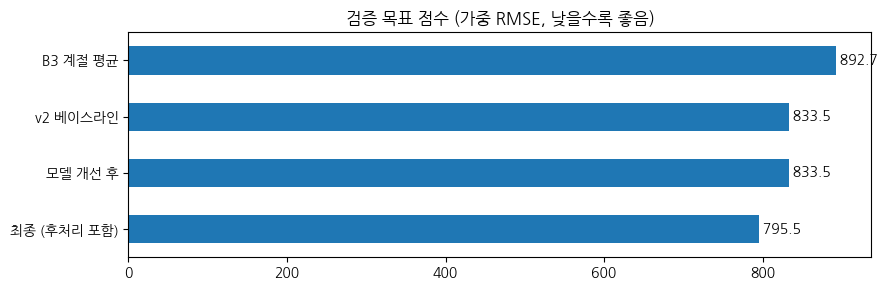

In [ ]:
# 전체 개선 요약: B3 → v2 → 모델 개선 → 후처리
summary = pd.DataFrame({
    'B3 계절 평균': b3_score,
    'v2 베이스라인': scores(OOF_V2.assign(pred=postprocess(OOF_V2, PP_DEFAULT))),
    '모델 개선 후': scores(best_oof.assign(pred=postprocess(best_oof, PP_DEFAULT))),
    '최종 (후처리 포함)': scores(best_oof, 'final'),
}).T
display(summary.round(1))

ax = summary['목표(가중)'].plot.barh(figsize=(9, 3), title='검증 목표 점수 (가중 RMSE, 낮을수록 좋음)')
for i, v in enumerate(summary['목표(가중)']):
    ax.text(v, i, f' {v:,.1f}', va='center')
ax.invert_yaxis(); plt.tight_layout(); plt.show()

# 10. 최종 학습 & 제출 파일

- 학습 데이터: 정답 날짜가 2023-03-03 이전인 전체 행
- **시드 3개로 학습해 평균** → 예측 흔들림 감소 (선택 과정이 아니라 과적합 위험 없음)
- 예측 시점 2023-03-03, 3/4 ~ 3/31 예측 → 후처리 적용
- 저장 파일 2개 (하루 제출 3회 → 리더보드로 후처리 효과도 확인 가능)
  - `submission_final.csv`: 모델 + 후처리 (**최종 제출 후보**)
  - `submission_no_pp.csv`: 모델만 (후처리 전)

In [ ]:
SEEDS = [0, 1, 2]
BASE_PARAMS = dict(best_params)
TEST = make_rows_x(np.array([last_known]))
TEST['ID'] = TEST['series'] + '_' + TEST['target'].dt.strftime('%Y%m%d')
TEST = TEST.set_index('ID').loc[sub.ID].reset_index()
TEST['b3'] = baseline_b3(TEST, '2023-03-03')

t0, parts, final_models = time.time(), [], []
for sd in SEEDS:
    m = fit_models(DS, best_cfg, seed=sd)
    final_models.append(m)
    parts.append(predict_parts(m, TEST, best_cfg))
TEST[['prob', 'price_A', 'price_B']] = sum(parts) / len(parts)
print(f'최종 학습 완료 ({time.time() - t0:.0f}초, 시드 {SEEDS})')

TEST['pred_final'] = postprocess(TEST, BEST_PP)
TEST['pred_no_pp'] = postprocess(TEST, PP_DEFAULT)

for col, fname in [('pred_final', 'submission_final.csv'), ('pred_no_pp', 'submission_no_pp.csv')]:
    s = sub[['ID']].assign(answer=TEST[col].values)
    assert s.answer.notna().all() and (s.answer >= 0).all() and len(s) == len(sub) and (s.ID == sub.ID).all()
    s.to_csv(OUT_DIR + fname, index=False, encoding='utf-8')
    print('저장:', OUT_DIR + fname, s.shape)
display(TEST[['ID', 'prob', 'price_A', 'price_B', 'b3', 'pred_no_pp', 'pred_final']].head(8))

최종 학습 완료 (122초, 시드 [0, 1, 2])
저장: /content/drive/MyDrive/ESAA/OB 프로젝트/ESAA_OB_Project3_data/submission_final.csv (1092, 2)
저장: /content/drive/MyDrive/ESAA/OB 프로젝트/ESAA_OB_Project3_data/submission_no_pp.csv (1092, 2)


,ID,prob,price_A,price_B,b3,pred_no_pp,pred_final
0,TG_A_J_20230304,0.985,"3,642.638","3,624.324","3,681.765","3,579.837","3,620.608"
1,TG_A_J_20230305,0.000,"3,277.192","3,486.894",0.000,1.137,0.000
2,TG_A_J_20230306,0.993,"3,722.405","3,663.831","3,903.667","3,669.090","3,762.921"
3,TG_A_J_20230307,0.990,"3,712.423","3,592.831","3,444.684","3,614.523","3,546.588"
4,TG_A_J_20230308,0.989,"3,742.713","3,678.473","3,619.421","3,671.038","3,650.391"
5,TG_A_J_20230309,0.988,"3,813.434","3,768.371","3,869.944","3,746.755","3,796.031"
6,TG_A_J_20230310,0.985,"3,733.874","3,785.519","3,979.167","3,703.172","3,813.570"
7,TG_A_J_20230311,0.980,"3,821.875","3,708.303","3,681.765","3,689.162","3,686.203"


,2023-03 예측,2022-03 실제,2021-03 실제
감귤,"3,495.000","3,776.000","2,828.000"
당근,832.000,490.000,508.000
무,315.000,293.000,241.000
브로콜리,"1,709.000","1,549.000","1,436.000"
양배추,433.000,446.000,291.000


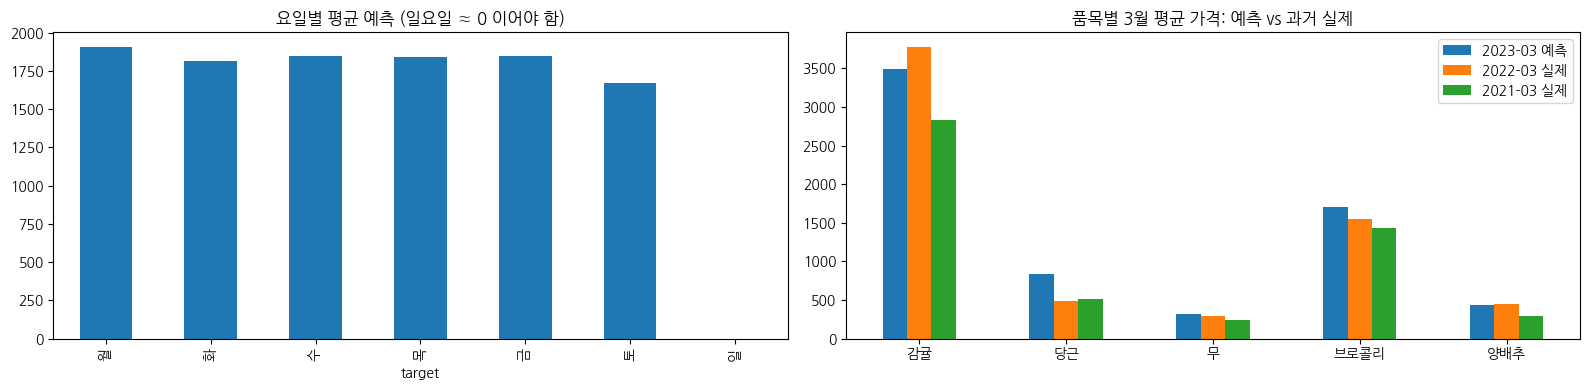

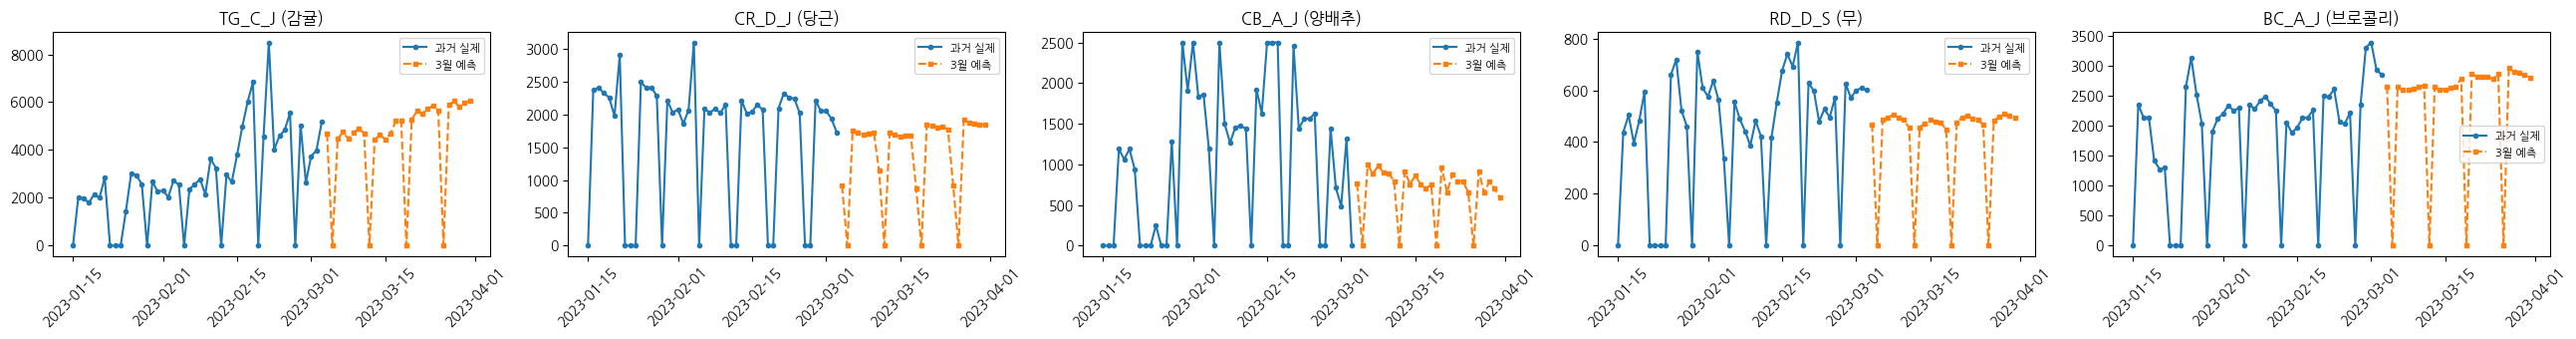

In [ ]:
# 제출 전 점검 ① 요일별 평균 예측(일요일 ≈ 0) ② 품목별 예측 vs 최근 3월 실제 ③ 대표 시계열 흐름
chk = TEST.assign(품목=TEST.series.str[:2].map(ITEM_KR))
mar = {yr: P.loc[f'{yr}-03-04':f'{yr}-03-31'].mean().groupby(item_of).mean().rename(ITEM_KR) for yr in [2021, 2022]}
item_chk = pd.DataFrame({'2023-03 예측': chk.groupby('품목').pred_final.mean(),
                         '2022-03 실제': mar[2022], '2021-03 실제': mar[2021]})
display(item_chk.round(0))

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
chk.groupby(chk.target.dt.dayofweek).pred_final.mean().rename(index=dict(enumerate('월화수목금토일'))).plot.bar(
    ax=ax[0], title='요일별 평균 예측 (일요일 ≈ 0 이어야 함)')
item_chk.plot.bar(ax=ax[1], title='품목별 3월 평균 가격: 예측 vs 과거 실제', rot=0)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(26, 3.5))
for ax, it in zip(axes, ITEMS):
    s = TEST[TEST.series.str[:2] == it].groupby('series').pred_final.sum().idxmax()
    hist = P.loc['2023-01-15':'2023-03-03', s]
    d = TEST[TEST.series == s]
    ax.plot(hist.index, hist.values, 'o-', ms=3, label='과거 실제')
    ax.plot(d.target, d.pred_final, 's--', ms=3, label='3월 예측')
    ax.set_title(f'{s} ({ITEM_KR[it]})'); ax.tick_params(axis='x', rotation=45); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# 11. 결과 분석 (발표 자료용)

발표 평가 기준에 맞춰 정리한다.
- **예측 정확성**: 위의 검증 RMSE 요약
- **예측 유의성 (가격 방향성)**: 거래가 있었던 날, 가격이 기준가격보다 오를지/내릴지 맞힌 비율
- **인사이트**: 품목별 오차 기여도, 예측 거리별 오차, 피처 중요도

In [ ]:
# 예측 유의성: 방향 정확도 (거래일만, 기준가격 대비 상승/하락)
t = best_oof[(best_oof.trade == 1) & best_oof.lev.notna()].copy()
price_hat = BEST_PP['w_A'] * t.price_A + (1 - BEST_PP['w_A']) * t.price_B
real_up = np.sign(t.y - t.lev)
dir_tab = pd.DataFrame({
    '모델': (np.sign(price_hat - t.lev) == real_up).groupby(t.fold).mean(),
    '항상 상승 예측': (real_up == 1).groupby(t.fold).mean(),
    '작년 변화율 따라가기': (np.sign(t.ly_ratio.fillna(1) - 1) == real_up).groupby(t.fold).mean(),
})
dir_tab.loc['평균'] = dir_tab.mean()
display((dir_tab * 100).round(1).astype(str) + '%')

,모델,항상 상승 예측,작년 변화율 따라가기
fold,,,
21-03,68.0%,56.5%,64.6%
22-03,70.8%,64.7%,56.5%
23-01,63.5%,58.0%,58.4%
23-02,68.4%,52.9%,63.3%
평균,67.7%,58.0%,60.7%


,오차 비중(%),v2 RMSE,최종 RMSE,평균 편향(예측−실제),개선폭
품목,,,,,
감귤,67.200,"1,354.100","1,273.900",-18.300,80.200
브로콜리,19.100,752.000,716.000,132.100,36.000
당근,9.200,555.300,563.400,-59.800,-8.100
양배추,3.100,405.500,384.400,2.300,21.100
무,1.500,218.200,213.000,7.300,5.300


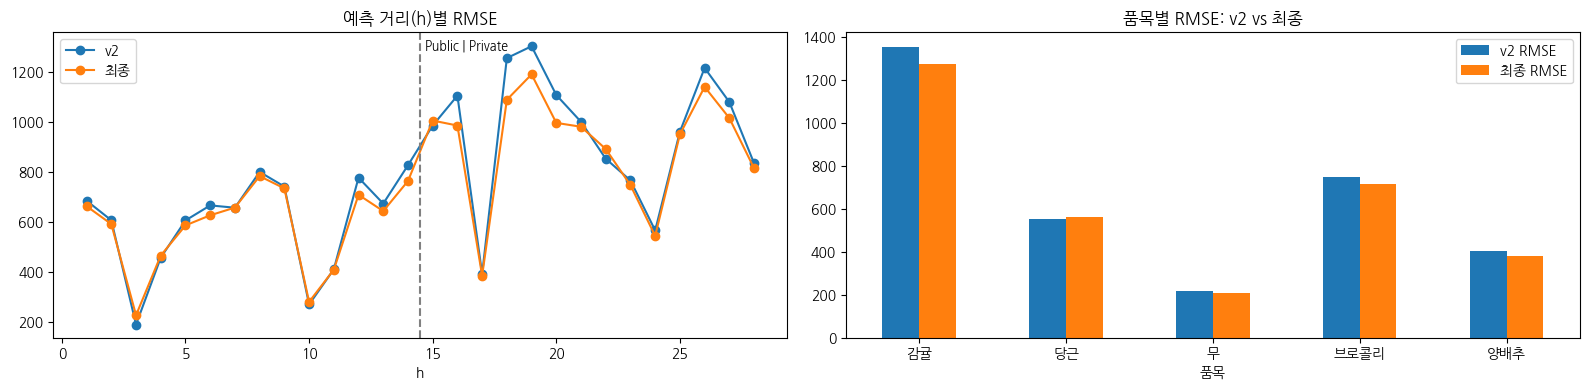

In [ ]:
# 품목별 오차 기여도: RMSE² = 행별 제곱오차 평균 → 품목별 제곱오차 합의 비중으로 점수 기여도를 나눔
best_oof['품목'] = best_oof.series.str[:2].map(ITEM_KR)
OOF_V2['품목'] = OOF_V2.series.str[:2].map(ITEM_KR)
sq_final = ((best_oof.y - best_oof.final) ** 2).groupby(best_oof.품목).sum()
item_tbl = pd.DataFrame({
    '오차 비중(%)': sq_final / sq_final.sum() * 100,
    'v2 RMSE': OOF_V2.groupby('품목').apply(lambda d: rmse(d.y, d.pred)),
    '최종 RMSE': best_oof.groupby('품목').apply(lambda d: rmse(d.y, d.final)),
    '평균 편향(예측−실제)': (best_oof.final - best_oof.y).groupby(best_oof.품목).mean(),
})
item_tbl['개선폭'] = item_tbl['v2 RMSE'] - item_tbl['최종 RMSE']
display(item_tbl.sort_values('오차 비중(%)', ascending=False).round(1))

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
for name, d, col in [('v2', OOF_V2, 'pred'), ('최종', best_oof, 'final')]:
    d.groupby('h').apply(lambda g: rmse(g.y, g[col])).plot(ax=ax[0], marker='o', label=name)
ax[0].axvline(14.5, c='gray', ls='--'); ax[0].text(14.7, ax[0].get_ylim()[1] * 0.95, 'Public | Private', fontsize=9)
ax[0].set_title('예측 거리(h)별 RMSE'); ax[0].legend()
item_tbl[['v2 RMSE', '최종 RMSE']].plot.bar(ax=ax[1], title='품목별 RMSE: v2 vs 최종', rot=0)
plt.tight_layout(); plt.show()

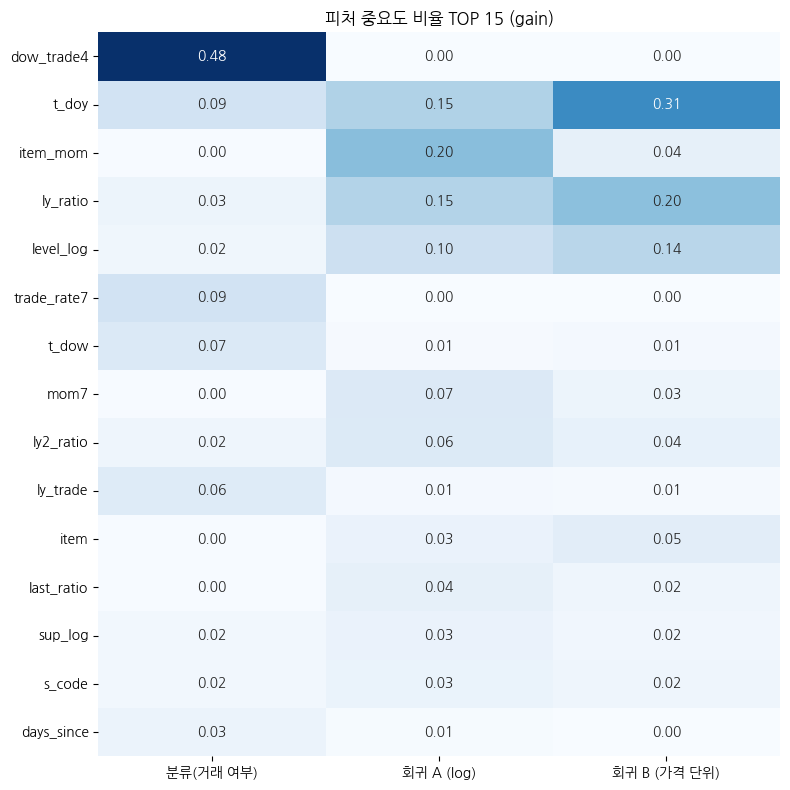

In [ ]:
# 피처 중요도 (최종 모델, 시드 0) — 세 모델이 각각 무엇을 보는지
m = final_models[0]
F = best_cfg['feats']
imp = pd.DataFrame({'분류(거래 여부)': m['clf'].booster_.feature_importance('gain'),
                    '회귀 A (log)': m['reg_a'].booster_.feature_importance('gain'),
                    '회귀 B (가격 단위)': m['reg_b'].booster_.feature_importance('gain')}, index=F)
imp = imp / imp.sum()
top = imp.loc[imp.max(axis=1).sort_values(ascending=False).index[:15]]
plt.figure(figsize=(8, 8))
sns.heatmap(top, annot=True, fmt='.2f', cmap='Blues', cbar=False)
plt.title('피처 중요도 비율 TOP 15 (gain)'); plt.tight_layout(); plt.show()
new_used = [f for f in NEW_FEATS if f in F]
if new_used:
    print('신규 피처 중요도 합:', (imp.loc[new_used].sum() * 100).round(1).astype(str).add('%').to_dict())

In [ ]:
# 최종 요약 출력 (발표 자료에 옮겨 적기용)
print('=' * 60)
print('최종 모델 설정')
print('  피처 수:', len(best_cfg['feats']), '| 시즌 가중치:', best_cfg['season_k'],
      '| 최근성 반감기:', best_cfg['half_life'], '| 트리:', best_params['n_estimators'], '/ lr', best_params['learning_rate'])
print('  후처리:', BEST_PP)
print('검증 점수 (가중 RMSE)')
for k, r in summary['목표(가중)'].items():
    print(f'  {k:<16}: {r:,.1f}')
print('방향 정확도 (평균):', f"{dir_tab.loc['평균', '모델']:.1%}", '| 항상 상승:', f"{dir_tab.loc['평균', '항상 상승 예측']:.1%}")
print('제출 파일:', OUT_DIR + 'submission_final.csv')
print('=' * 60)

최종 모델 설정
  피처 수: 24 | 시즌 가중치: 2.0 | 최근성 반감기: None | 트리: 400 / lr 0.05
  후처리: {'sunday0': True, 'w_A': 0.5, 'lo': 0.0, 'hi': 1.0, 'scale': 1.0, 'w_b3': 0.4, 'w_b3_long': None}
검증 점수 (가중 RMSE)
  B3 계절 평균        : 892.7
  v2 베이스라인        : 833.5
  모델 개선 후         : 833.5
  최종 (후처리 포함)     : 795.5
방향 정확도 (평균): 67.7% | 항상 상승: 58.0%
제출 파일: /content/drive/MyDrive/ESAA/OB 프로젝트/ESAA_OB_Project3_data/submission_final.csv


# 📌 정리

**방법**
- 가격을 **거래 확률 × 기준가격 × 변화율**로 나눠 예측 (60%가 거래 없는 날이라 0과 가격을 따로 다룸)
- 변화율은 회귀 2개(log·huber / 가격 단위·기준가격² 가중)를 섞어 서로의 편향을 상쇄
- 실험과 후처리는 **4개 검증 시점 × 채택 규칙**으로 자동 선택 → 특정 기간에 맞춘 과적합 방지

**결과 확인 위치**
- 실험별 점수: 8번 표 / 후처리 단계별 점수: 9번 표 / 전체 개선 요약: 9번 막대그래프
- 발표용: 방향 정확도(예측 유의성), 품목별 오차 기여도, 피처 중요도 (11번)

**다음 단계 아이디어**
1. 감귤이 오차의 대부분 → 감귤 전용 모델 또는 감귤 회귀에 별도 파라미터
2. 리더보드에서 `submission_final.csv`와 `submission_no_pp.csv`를 비교해 후처리 효과 확인
3. 하이퍼파라미터 탐색 (num_leaves, min_child_samples) — 같은 채택 규칙으로